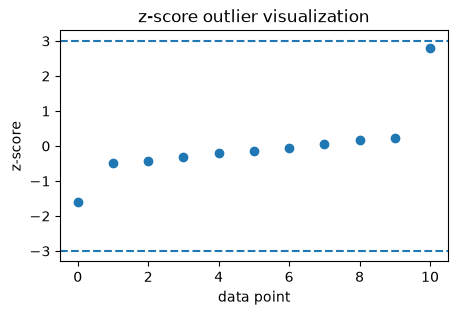

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([-20,10,12,15,18,20,22,25,28,30,100])

z_score = zscore(data)
plt.figure(figsize=(5,3))
plt.scatter(range(len(data)),z_score)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle='--')

plt.xlabel("data point")
plt.ylabel("z-score")
plt.title("z-score outlier visualization")

plt.show()

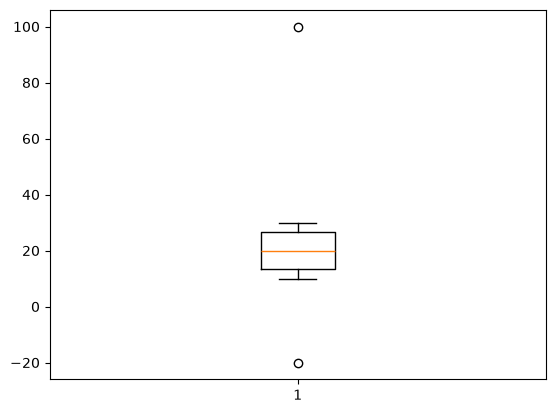

In [8]:
plt.boxplot(data)
plt.show()

In [ ]:
import seaborn as sns
df=sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [32]:
q1 = df['total_bill'].quantile(0.25)
q3 = df['total_bill'].quantile(0.75)

iqr=q3-q1

lower = q1-1.5*iqr
upper= q3+1.5*iqr

df[(df['total_bill']<upper) & (df['total_bill']>lower)]

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


lower value= -0.34375
upper value= 5.90625


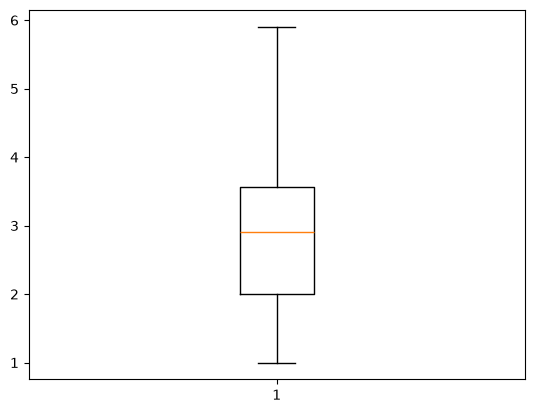

In [40]:
q1 = df['tip'].quantile(0.25)
q3 = df['tip'].quantile(0.75)

iqr=q3-q1

lower = q1-1.5*iqr
upper= q3+1.5*iqr

print('lower value=', lower)
print('upper value=', upper)

df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])
plt.show()

In [61]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
import pandas as pd

num_feat=['total_bill']
cat_feat=['sex', 'smoker']
min_max_feat=['tip']

transformer= ColumnTransformer(
    transformers = [('num', StandardScaler(), num_feat),
    ('cat', OneHotEncoder(drop='first'), cat_feat),
    ('min max', MinMaxScaler(), min_max_feat)], remainder='passthrough'
)

data_transformed = transformer.fit_transform(df)

df_transformed = pd.DataFrame(
    data_transformed,
    columns=transformer.get_feature_names_out()
)
df_transformed

,num__total_bill,cat__sex_Male,cat__smoker_Yes,min max__tip,remainder__day,remainder__time,remainder__size
0,-0.314711,0.0,0.0,0.002038,Sun,Dinner,2
1,-1.063235,1.0,0.0,0.134522,Sun,Dinner,3
2,0.13778,1.0,0.0,0.509554,Sun,Dinner,3
3,0.438315,1.0,0.0,0.470828,Sun,Dinner,2
4,0.540745,0.0,0.0,0.531975,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,1.0,0.0,1.0,Sat,Dinner,3
240,0.832275,0.0,1.0,0.203822,Sat,Dinner,2
241,0.32463,1.0,1.0,0.203822,Sat,Dinner,2
242,-0.221287,1.0,0.0,0.152866,Sat,Dinner,2
